# Imports

In [1]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from collections import Counter

# Preprocessing

In [2]:
def tokenize(data):
  X = data['sms']
  Y = data['label']


  analyzer = CountVectorizer(token_pattern=r"(?u)\b\w+\b").build_analyzer()
  X = X.apply(analyzer)


  return X, Y



# Naive Bayes Class

In [ ]:
class LaplaceNaiveBayes:


  def train(self, X_train, Y_train):

      #1.1.- TODO: Define your prior probabilities
      classes = np.unique(Y_train)
      self.priors = {}

      for cls in classes:
        self.priors[cls] = np.sum(Y_train == cls) / len(Y_train)

      # 1.2.- TODO: Find V and its size |V|:
      self.V = set(word 
        for message in X_train 
        for word in message
        )

      # 1.3.- Likelihood table P(X = x_i | Y = y_k) using Laplace smoothing (Equation 1).
      # You may need loops, or find a way to vectorize.
      # TODO: count(x_i, y_k) for each word and class
      word_in_class = {}
      total_words_in_class = {}

      for cls in classes:
          class_messages = [
              message
              for message, label in zip(X_train, Y_train)
              if label == cls
          ]

          word_counts = Counter(
              word
              for message in class_messages
              for word in message
          )

          word_in_class[cls] = word_counts

          # Total word occurrences in this class
          total_words_in_class[cls] = sum(word_counts.values())
      
      # TODO : Save all the conditionals into the table
      self.likelihood_table = {}

      for cls in classes:
          self.likelihood_table[cls] = {}

          for word in self.V:
              self.likelihood_table[cls][word] = (
                  (word_in_class[cls][word] + 1)
                  / (total_words_in_class[cls] + len(self.V))
              )

  def predict(self, X_test):
    # 2.- TODO: For each message, compute a score for each class:
    # log P(Y = y_k) + sum_i log P(X = x_i | Y = y_k)
    # Skip any word that is not in self.V.
    # (Summing logs avoids underflow from multiplying many small probabilities.)
    y_pred = []

    for message in X_test:
      scores = {}

      for cls in self.priors:
        log_prior = np.log(self.priors[cls])

        log_prob = sum(
          np.log(self.likelihood_table[cls][word])
          for word in message
          if word in self.V
        )

        scores[cls] = log_prior + log_prob
      
      predicted_class = max(scores, key=scores.get)
      y_pred.append(predicted_class)

    return y_pred


#Data Loading and Model Call

Accuracy: 0.9845
Confusion Matrix:
 [[1444    5]
 [  21  203]]


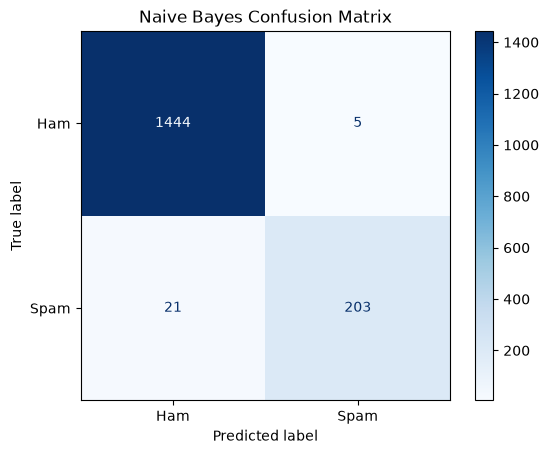

In [ ]:
#we initialize our model object
model = LaplaceNaiveBayes()

# We load our data and tokenize:
df = pd.read_parquet("hf://datasets/ucirvine/sms_spam/plain_text/train-00000-of-00001.parquet")

# Note: X and Y are pandas Series (1-D). X.iloc[i] is the i-th message as a list of
# words (messages have different lengths, and repeated words are kept), and
# Y.iloc[i] is its label (0 = ham, 1 = spam).
X,Y = tokenize(df)

#We split our data
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, stratify=Y, random_state=0)


#train our model with our data
model.train(X_train, Y_train)

#2.- classify new data
y_pred = model.predict(X_test)

#3.- Report accuracy of your model and plot the confusion matrix
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

accuracy = accuracy_score(Y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

cm = confusion_matrix(Y_test, y_pred, labels=[0, 1])
print("Confusion Matrix:\n", cm)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues")
plt.title("Naive Bayes Confusion Matrix")
plt.savefig("confusion_matrix.png")
plt.show()